# Clean Dataset YOLOv8 Preprocessing

This notebook prepares the new `clean dataset/` folder for YOLOv8 license plate detection.

Input format:
- `clean dataset/Vehicle*.jpg`
- `clean dataset/Vehicle*.txt`
- `clean dataset/classes.txt`

Output format:
- `clean_dataset_processed/train/images`
- `clean_dataset_processed/train/labels`
- `clean_dataset_processed/valid/images`
- `clean_dataset_processed/valid/labels`
- `clean_dataset_processed/test/images`
- `clean_dataset_processed/test/labels`
- `clean_dataset_processed/data.yaml`

The output folder is `clean_dataset_processed/` so it does not overwrite the previous `dataset_processed/` folder. In the YOLOv8 notebook, use `clean_dataset_processed/data.yaml` as the training data path for the clean dataset experiment.

## 1. Configuration

In [1]:
from pathlib import Path
import csv
import random
import re
import shutil
from collections import Counter

SOURCE_DATASET = Path("clean dataset")
OUTPUT_DATASET = Path("clean_dataset_processed")

SPLITS = ["train", "valid", "test"]
SPLIT_RATIOS = {"train": 0.80, "valid": 0.10, "test": 0.10}
RANDOM_SEED = 42
REBUILD_OUTPUT = True

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_NAME = "license_plate"

print("Source dataset:", SOURCE_DATASET.resolve())
print("YOLOv8 output dataset:", OUTPUT_DATASET.resolve())

Source dataset: D:\thesis model training\clean dataset
YOLOv8 output dataset: D:\thesis model training\clean_dataset_processed


## 2. Scan and Validate the Clean Dataset

The new dataset already contains plate-level YOLO labels. This cell validates the labels and normalizes every class id to class `0`, named `license_plate`.

In [2]:
def natural_key(path):
    return [int(part) if part.isdigit() else part.lower() for part in re.split(r"(\d+)", path.name)]


def parse_yolo_label(label_path):
    normalized_lines = []
    original_classes = []

    for line_number, raw_line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
        line = raw_line.strip()
        if not line:
            continue

        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f"{label_path.name}:{line_number} should have 5 values, found {len(parts)}")

        class_id_raw, x_raw, y_raw, width_raw, height_raw = parts
        try:
            class_id = int(float(class_id_raw))
            x_center = float(x_raw)
            y_center = float(y_raw)
            width = float(width_raw)
            height = float(height_raw)
        except ValueError as exc:
            raise ValueError(f"{label_path.name}:{line_number} contains a non-numeric value") from exc

        if not (0.0 <= x_center <= 1.0 and 0.0 <= y_center <= 1.0):
            raise ValueError(f"{label_path.name}:{line_number} has center outside [0, 1]")
        if not (0.0 < width <= 1.0 and 0.0 < height <= 1.0):
            raise ValueError(f"{label_path.name}:{line_number} has invalid box size")

        normalized_lines.append(f"0 {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")
        original_classes.append(class_id)

    return normalized_lines, original_classes


assert SOURCE_DATASET.exists(), f"Missing source dataset folder: {SOURCE_DATASET}"

classes_file = SOURCE_DATASET / "classes.txt"
if classes_file.exists():
    print("Original classes.txt:")
    print(classes_file.read_text(encoding="utf-8").strip())

image_paths = sorted(
    [path for path in SOURCE_DATASET.iterdir() if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS],
    key=natural_key,
)

records = []
missing_labels = []
class_counter = Counter()
total_boxes = 0

for image_path in image_paths:
    label_path = SOURCE_DATASET / f"{image_path.stem}.txt"
    if not label_path.exists():
        missing_labels.append(image_path.name)
        continue

    normalized_lines, original_classes = parse_yolo_label(label_path)
    class_counter.update(original_classes)
    total_boxes += len(normalized_lines)
    records.append({
        "image_path": image_path,
        "label_path": label_path,
        "label_lines": normalized_lines,
        "box_count": len(normalized_lines),
    })

assert image_paths, f"No images found in {SOURCE_DATASET}"
assert not missing_labels, f"Images without matching label files: {missing_labels[:10]}"

print(f"Images found: {len(image_paths)}")
print(f"Valid image-label pairs: {len(records)}")
print(f"Total plate boxes: {total_boxes}")
print(f"Original class ids found: {dict(class_counter)}")

Original classes.txt:
LP
Images found: 1929
Valid image-label pairs: 1929
Total plate boxes: 1986
Original class ids found: {0: 1986}


## 3. Split Into Train, Validation, and Test Sets

In [3]:
def split_records(records, ratios, seed):
    assert set(ratios) == set(SPLITS), f"Ratios must contain exactly these splits: {SPLITS}"
    assert abs(sum(ratios.values()) - 1.0) < 1e-9, "Split ratios must sum to 1.0"

    shuffled = list(records)
    random.Random(seed).shuffle(shuffled)

    total = len(shuffled)
    train_count = int(total * ratios["train"])
    valid_count = int(total * ratios["valid"])
    test_count = total - train_count - valid_count

    return {
        "train": shuffled[:train_count],
        "valid": shuffled[train_count:train_count + valid_count],
        "test": shuffled[train_count + valid_count:],
    }


split_map = split_records(records, SPLIT_RATIOS, RANDOM_SEED)

for split in SPLITS:
    split_boxes = sum(record["box_count"] for record in split_map[split])
    print(f"{split}: {len(split_map[split])} images, {split_boxes} boxes")

train: 1543 images, 1593 boxes
valid: 192 images, 194 boxes
test: 194 images, 199 boxes


## 4. Write the YOLOv8 Dataset

In [4]:
def is_safe_output_path(path):
    root = Path.cwd().resolve()
    target = path.resolve()
    source = SOURCE_DATASET.resolve()

    if target == root or target == source:
        return False
    try:
        target.relative_to(root)
    except ValueError:
        return False
    return True


if OUTPUT_DATASET.exists():
    if not REBUILD_OUTPUT:
        raise FileExistsError(f"Output dataset already exists: {OUTPUT_DATASET}")
    assert is_safe_output_path(OUTPUT_DATASET), f"Refusing to rebuild unsafe output path: {OUTPUT_DATASET}"
    shutil.rmtree(OUTPUT_DATASET)

manifest_rows = []

for split in SPLITS:
    output_images = OUTPUT_DATASET / split / "images"
    output_labels = OUTPUT_DATASET / split / "labels"
    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    for record in split_map[split]:
        image_path = record["image_path"]
        label_path = record["label_path"]
        output_image_path = output_images / image_path.name
        output_label_path = output_labels / label_path.name

        shutil.copy2(image_path, output_image_path)
        label_text = "\n".join(record["label_lines"])
        output_label_path.write_text(label_text + ("\n" if label_text else ""), encoding="utf-8")

        manifest_rows.append({
            "split": split,
            "image": image_path.name,
            "label": label_path.name,
            "boxes": record["box_count"],
            "source_image": str(image_path),
            "source_label": str(label_path),
        })

data_yaml = f"""train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: {CLASS_NAME}
"""

(OUTPUT_DATASET / "data.yaml").write_text(data_yaml, encoding="utf-8")
(OUTPUT_DATASET / "classes.txt").write_text(f"{CLASS_NAME}\n", encoding="utf-8")

with (OUTPUT_DATASET / "split_manifest.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["split", "image", "label", "boxes", "source_image", "source_label"])
    writer.writeheader()
    writer.writerows(manifest_rows)

print(f"Dataset written to: {OUTPUT_DATASET.resolve()}")
print("\ndata.yaml:")
print((OUTPUT_DATASET / "data.yaml").read_text(encoding="utf-8"))

Dataset written to: D:\thesis model training\clean_dataset_processed

data.yaml:
train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: license_plate



## 5. Verify the Output Dataset

In [5]:
def verify_yolo_label(label_path):
    errors = []
    box_count = 0

    for line_number, raw_line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
        line = raw_line.strip()
        if not line:
            continue

        parts = line.split()
        if len(parts) != 5:
            errors.append(f"line {line_number}: expected 5 values")
            continue

        class_id, x_center, y_center, width, height = parts
        values = [float(x_center), float(y_center), float(width), float(height)]
        if class_id != "0":
            errors.append(f"line {line_number}: class id is not 0")
        if not (0.0 <= values[0] <= 1.0 and 0.0 <= values[1] <= 1.0):
            errors.append(f"line {line_number}: center outside [0, 1]")
        if not (0.0 < values[2] <= 1.0 and 0.0 < values[3] <= 1.0):
            errors.append(f"line {line_number}: invalid width/height")

        box_count += 1

    return box_count, errors


all_errors = []

for split in SPLITS:
    image_dir = OUTPUT_DATASET / split / "images"
    label_dir = OUTPUT_DATASET / split / "labels"
    images = sorted([path for path in image_dir.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS], key=natural_key)
    labels = sorted(label_dir.glob("*.txt"), key=natural_key)

    split_box_count = 0
    for label_path in labels:
        box_count, errors = verify_yolo_label(label_path)
        split_box_count += box_count
        for error in errors:
            all_errors.append(f"{split}/{label_path.name}: {error}")

    print(f"{split}: {len(images)} images, {len(labels)} labels, {split_box_count} boxes")
    assert len(images) == len(labels), f"Image/label count mismatch in {split}"

assert not all_errors, "Label validation errors:\n" + "\n".join(all_errors[:20])
print("Output dataset verification passed.")

train: 1543 images, 1543 labels, 1593 boxes
valid: 192 images, 192 labels, 194 boxes
test: 194 images, 194 labels, 199 boxes
Output dataset verification passed.


## 6. Visualize One Training Sample

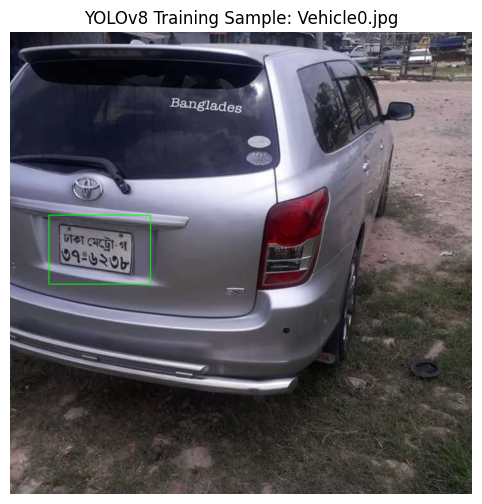

In [6]:
try:
    import cv2
    import matplotlib.pyplot as plt

    sample_label = next(
        path for path in (OUTPUT_DATASET / "train" / "labels").glob("*.txt")
        if path.read_text(encoding="utf-8").strip()
    )
    sample_image = next(
        path for path in (OUTPUT_DATASET / "train" / "images").iterdir()
        if path.stem == sample_label.stem and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    image = cv2.cvtColor(cv2.imread(str(sample_image)), cv2.COLOR_BGR2RGB)
    image_height, image_width = image.shape[:2]

    for line in sample_label.read_text(encoding="utf-8").splitlines():
        class_id, x_center, y_center, box_width, box_height = line.split()
        x_center = float(x_center)
        y_center = float(y_center)
        box_width = float(box_width)
        box_height = float(box_height)

        x1 = int((x_center - box_width / 2) * image_width)
        y1 = int((y_center - box_height / 2) * image_height)
        x2 = int((x_center + box_width / 2) * image_width)
        y2 = int((y_center + box_height / 2) * image_height)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.title(f"YOLOv8 Training Sample: {sample_image.name}")
    plt.axis("off")
    plt.show()
except Exception as exc:
    print("Visualization skipped:", exc)

## 7. Next Step

After this notebook finishes, `clean_dataset_processed/data.yaml` is ready for YOLOv8 training. In `yolov8_workflow.ipynb`, update the dataset path for this clean-dataset experiment to `clean_dataset_processed/data.yaml`.